# DM2026 Lab 2 — Homework: Twitter Emotion Classification
## V7 · Semantic Embedding Fusion & Triple Ensemble

### Student Information

- **GitHub ID:** `momoko-1234` *(check against your submitted repository)*
- **Kaggle name:** `momoko1234` *(check against your Kaggle account)*
### Kaggle Leaderboard Screenshot

**momoko1234** ranked **63rd** with a displayed score of **0.6276**. The screenshot shows the Leaderboard page for the 2026 DM LAB 2 Private Competition.

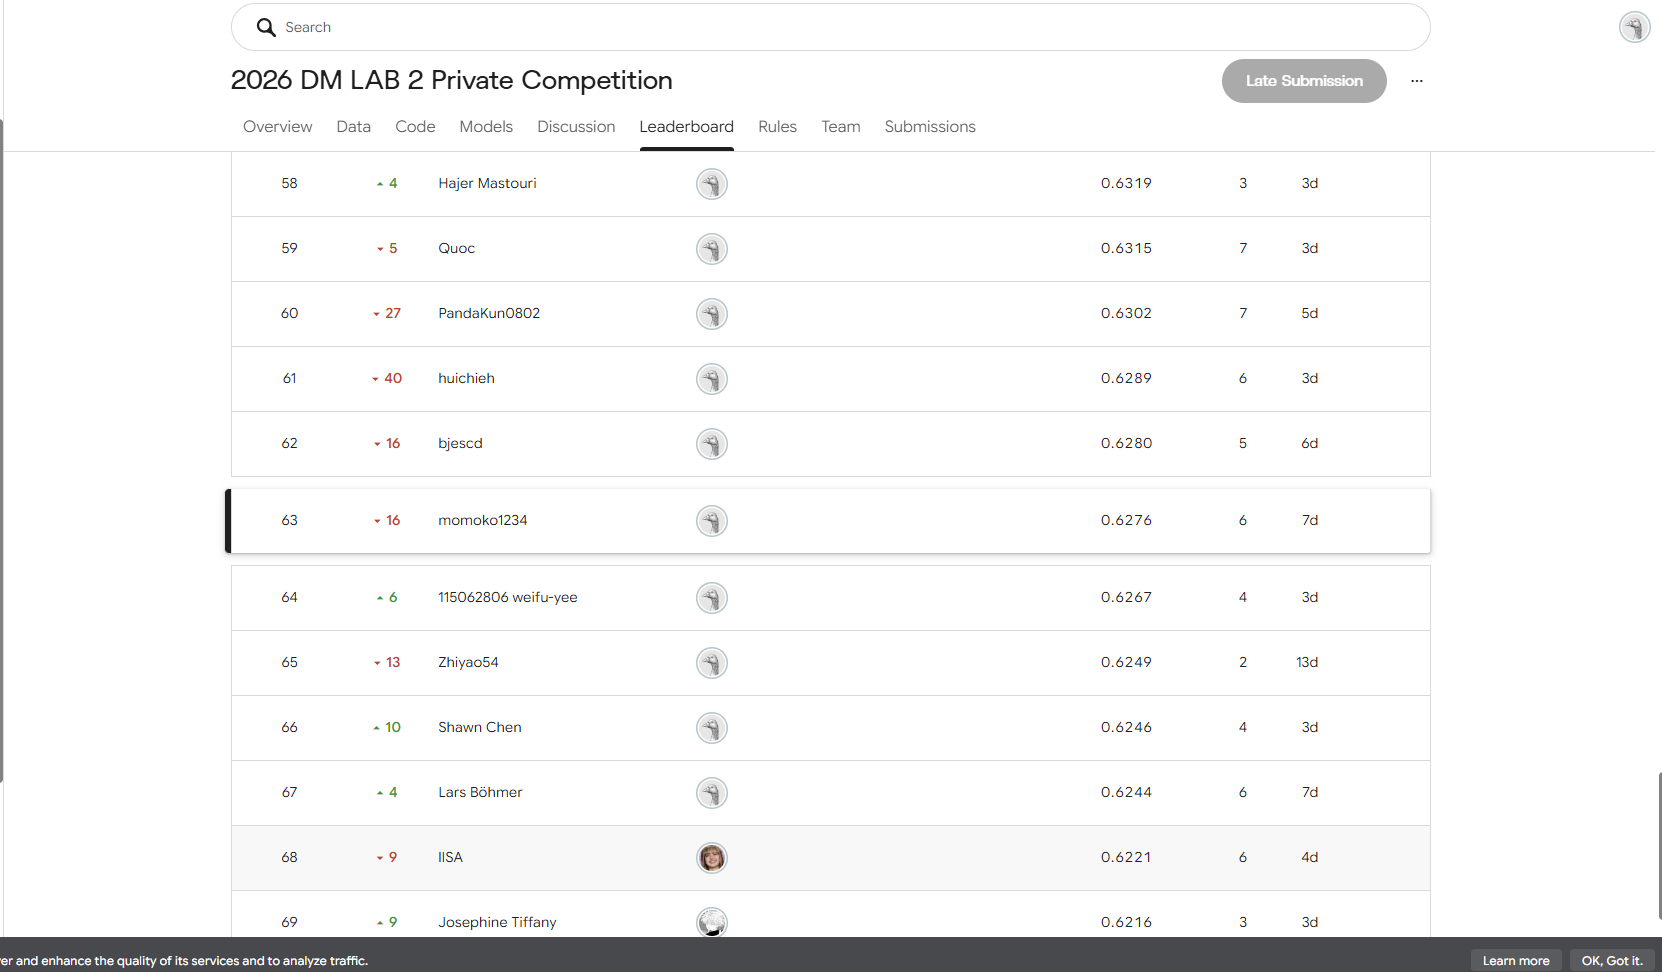
- **Submission notebook filename:** `DM2026-Lab2-Homework.ipynb`

> **Final submitted approach:** V7 Triple Ensemble, comprising 50% emotion-specialized DistilRoBERTa (V6 FULL), 25% BGE embeddings + Logistic Regression, and 25% BGE embeddings + CatBoost. This report documents the V7 model, rather than the later exploratory V8–V11 extensions.

### Summary of observed V7 performance

| Measure | Observed result | Source / qualification |
|---|---:|---|
| **5-fold OOF Macro F1** | **0.6309** | 3,360 labeled training examples; pooled OOF |
| OOF Accuracy | 0.6494 | Same held-out OOF predictions |
| OOF Weighted F1 | 0.6459 | Same held-out OOF predictions |
| OOF Multiclass Log Loss | 1.0293 | Same OOF probability distributions |
| **Kaggle Public Score** | **0.6288** | Previously reported accepted V7 submission; not recalculated in this notebook |
| Kaggle Private Score | *Not provided* | Add actual score/ranking only if available |

**Important:** The observed metrics above summarize a prior successful V7 experiment. The source code below is preserved for reproducibility, but no new Kaggle training execution is claimed by this edited report. The Kaggle Public Score is different from five-fold OOF validation.

### Notebook organization

The notebook follows the course's required sequence: **Project Report** (Preprocessing, Feature Engineering, Model Explanation, AI Prompts) followed by **Competition Code** (Preprocessing, Feature Engineering, Model Implementation). The original V7 implementation remains below and still exports `/kaggle/working/submission.csv` with the required `id,label` columns and 1,440 rows.

---
# Project Report

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

**Task and dataset.** The objective is to classify English Twitter-style posts into six emotions: **anger, disgust, fear, joy, sadness, and surprise**. I used the competition-provided files `final_posts.json` (post IDs and text), `data_identification.csv` (train/test identification), `emotion.csv` (labeled training emotions), and `sampleSubmission.csv` (required prediction ordering). They were joined using the unique `post_id` key and one-to-one merge validation. The complete dataset contains **4,800 posts**, of which **3,360 are labeled training posts** and **1,440 are unlabeled test posts**.

**Cleaning and text handling.** I checked for missing text, duplicate IDs, missing training labels, and consistency between the test IDs and the sample submission. I retained the original social-media language rather than aggressively removing punctuation, misspellings, and informal expressions, because these may convey emotion. Tokenization follows the requirements of each pretrained model: the emotion-specialized DistilRoBERTa branch uses a maximum length of **128 tokens**, while BGE representations use **256 tokens**. The competition's six labels were mapped to a fixed class order for consistent probability aggregation.

**Validation and data leakage prevention.** I used **five-fold StratifiedKFold** with `shuffle=True` and `random_state=42`. Each training observation was evaluated only by the model trained on the other four folds, producing **out-of-fold (OOF) probabilities**. TF-IDF-style learning is not the main feature in this V7 version; Logistic Regression and CatBoost are fitted exclusively on their respective fold's training embeddings. Optional emotion-score standardization is also fitted only inside the training partition. The pretrained encoders are frozen for embedding extraction, while V6 full fine-tuning occurs only on the relevant training folds. The test set provides no target labels and is used only for inference.

### 1.2 Feature Engineering Steps

I designed two complementary representation branches because my previous V6 model demonstrated good emotion recognition but still confused **disgust** with **anger**.

**(1) Emotion-specific contextual features (V6 FULL).** I used `j-hartmann/emotion-english-distilroberta-base`, an emotion-specialized pretrained Transformer. Because the original model contains a neutral class but this competition requires six classes, I preserved the six matching classifier rows by their label names and removed the neutral output. The model was fine-tuned on each fold's labeled training subset. It produced six-class probabilities for that fold's held-out examples and the competition test set.

**(2) General semantic sentence embeddings (BGE).** I used the frozen `BAAI/bge-base-en-v1.5` sentence encoder. For each post, the model generated a **768-dimensional semantic representation** using the first-token (`[CLS]`) embedding and **L2 normalization**. These vectors were used to train two separate downstream classifiers, **Logistic Regression** and **CatBoost**. The encoder itself was not fine-tuned using the competition labels.

**(3) Emotion-feature ablation.** I also explored concatenating frozen, label-free emotion-model probability features with BGE vectors. The probability features were log-transformed, standardized using only each fold's training data, and scaled before classification. This was an ablation study; it did not replace the principal BGE-only branches. The final chosen triple uses the BGE-only Logistic Regression and CatBoost outputs.

**Why these features?** Emotion-specialized Transformers can capture task-specific emotional meaning, while general semantic embeddings capture broader relationships between phrases. Even when a semantic branch is weaker on its own, its mistakes may differ from the fine-tuned model's errors, making a probability ensemble more effective.

### 1.3 Explanation of Your Model

**Architecture.** The selected V7 model is a **soft-voting Triple Ensemble** of three branches:

| Component | Method | Weight |
|---|---|---:|
| Emotion-specific classifier | Full fine-tuning of DistilRoBERTa (V6 FULL) | **50%** |
| General semantic classifier A | Frozen BGE embeddings + Logistic Regression | **25%** |
| General semantic classifier B | Frozen BGE embeddings + CatBoost | **25%** |

For an example \(x\), its final class probability is:

\[
P(y=c\mid x)=0.50P_{\mathrm{V6}}(c\mid x)+0.25P_{\mathrm{BGE-LR}}(c\mid x)+0.25P_{\mathrm{BGE-CatBoost}}(c\mid x).
\]

The predicted class is the emotion with the highest combined probability. Five separately trained models per branch contribute test predictions, which are averaged before the final soft vote.

**Training configuration.** V6 full fine-tuning used **3 epochs**, encoder learning rate `1e-5`, classifier-head learning rate `5e-5`, training batch size `8`, gradient accumulation `2`, warm-up ratio `0.1`, and weight decay `0.01`. The BGE + Logistic Regression branch used `C=2.0` and balanced class weights. BGE + CatBoost used **350 iterations**, depth `5`, learning rate `0.05`, and automatic class weighting. The random seed was fixed at `42` to improve reproducibility.

**Evaluation.** I prioritized **Macro F1** because the six classes have unequal sample sizes and the competition uses F1 for scoring. I also inspected Accuracy, Weighted F1, Log Loss, fold-level improvements, per-class F1, prediction agreement, and confusion patterns. The five-fold OOF procedure evaluates every labeled post once as held-out data.

#### Verified results from the previous V7 run

| Model / result | Macro F1 | Interpretation |
|---|---:|---|
| V6 FULL | **0.6194** | Previous emotion-specialized baseline (OOF) |
| V6 + BGE CatBoost (50:50) | **0.6300** | OOF ensemble experiment |
| V6 + BGE Logistic Regression (50:50) | **0.6297** | OOF ensemble experiment |
| **V7 Triple 50:25:25** | **0.6309** | **Selected V7 OOF model** |

The triple ensemble improves pooled Macro F1 by approximately **0.0115** compared with V6 FULL. The previously accepted V7 Kaggle submission obtained a **Public Score of 0.6288**; its Private Score has not been supplied here and is intentionally not invented. Results of different experiments should not be described as independent holdout confirmation when the same OOF data were used for model development.

#### V7 per-class performance (OOF)

| Emotion | F1 | Interpretation |
|---|---:|---|
| Anger | 0.6111 | Moderate recognition; some overlap with disgust |
| Disgust | **0.4781** | Hardest class; often confused with anger |
| Fear | 0.6549 | Relatively strong |
| Joy | **0.7598** | Strongest class |
| Sadness | 0.6561 | Relatively strong |
| Surprise | 0.6253 | Moderate performance |

**Limitations and interpretation.** Emotion classes can overlap semantically, especially **anger** and **disgust**; V7 still misclassified **126 disgust examples as anger** in the historical OOF analysis. Some social-media examples are ambiguous even to human readers, and class imbalance affects performance. Although BGE complements task-specific representations, the chosen mixture weights were explored on the same OOF dataset; therefore, OOF gains should be interpreted as development results rather than a guarantee of improvement on unseen future data. Pretrained models also use external data, and possible overlap with publicly available competition texts cannot be ruled out by OOF alone.

**Final decision.** I selected **V7 Triple 50:25:25** because it improved the previous V6 baseline while remaining reproducible, producing valid probability distributions and a competition submission in the required format. The later V8–V11 explorations are not part of the V7 implementation or the reported V7 Kaggle Public Score.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

**AI tools and roles.** I used **ChatGPT (GPT-6)** to discuss model alternatives, structure the experimental comparisons, draft and debug Python notebook code, and improve clarity of the written model explanation. I personally selected the final V7 model based on validation evidence. AI did not provide the competition's hidden labels and did not substitute for actual Kaggle scoring.

**AI suggestion (methodology summary, not represented as a verbatim user message):** Combine a task-specific emotion Transformer with frozen BGE semantic embeddings, train Logistic Regression and CatBoost classifiers independently on the same five outer folds, and ensemble the three sets of class probabilities with fixed weights. Compare pooled OOF F1 and inspect the confusion matrix before selecting the final model.

**My decision and why:** I adopted semantic ensemble learning because V6 FULL already had reasonable emotion recognition but struggled to differentiate disgust from anger. I wanted to test whether general semantic representations could correct different errors. I evaluated BGE + Logistic Regression and BGE + CatBoost both individually and in combination with V6, and selected the **50:25:25** soft-voting configuration based on the observed OOF performance and the accepted V7 competition submission.

**Code support and review.** AI assisted with drafting code and proposing validation checks (unique post IDs, identical class order, fold alignment, finite probabilities, no duplicate test rows, and `id,label` output). The actual model scores cited in this report come from the recorded experiments, not from AI estimates.

**Known project prompts (verbatim from the project discussion):**

These prompts cover model development and later experiments, including V8 and V9. Section 1.3 describes the final V7 ensemble.

**Prompt 1:**
> 你看一些論文給我一些可以提分以及嘗試的方向

**Prompt 2:**
> 直接規劃可驗證的實驗帶我驗證給我code

**Prompt 3:**
> V8 採用 Label-aware Contrastive Learning + Hard 試試看

**Prompt 4:**
> V9：Noise-aware Emotion Classification（標籤噪音感知情緒分類）

**Prompt 5:**
> D：另外訓練一個 Anger／Disgust 二元專家模型

**Prompt 6:**
> 有個老師說引用外部資料庫就是先將訓練集丟給AI然後再進去跑

**Prompt 7:**
> 1. 把訓練資料給 ChatGPT／Gemini，讓 AI 重新分析情緒，再拿分析結果訓練模型。

**Prompt 8:**
> 給我其他方法吧

**Prompt 9:**
> 根據老師教材回家作業給我新的一版notebook

---

---
# Competition Code
## 1. Preprocessing Steps
### 1.0 Environment, configuration and reproducibility

In [1]:
# Kaggle usually provides these packages; uncomment installation only if needed.
# %pip -q install transformers safetensors scikit-learn
import os, gc, json, hashlib, math, time, random
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, log_loss
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, set_seed
from torch.utils.data import Dataset, DataLoader

SEED = 42
LABELS = ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
LABEL2ID = {s:i for i,s in enumerate(LABELS)}
ID2LABEL = {i:s for s,i in LABEL2ID.items()}
MODEL_NAME = 'j-hartmann/emotion-english-distilroberta-base'
# If using offline weights, set this to the attached complete model directory.
MODEL_SOURCE = os.environ.get('V6_MODEL_SOURCE', MODEL_NAME)
MAX_LENGTH = 128
N_SPLITS = 5
EPOCHS = 3
ENCODER_LR = 1e-5
HEAD_LR = 5e-5
TRAIN_BATCH = 8
EVAL_BATCH = 32
GRAD_ACCUM = 2
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
TRAIN_MODES = ['full']  # only FULL is needed for V7
PRIMARY_MODE = 'full'
DEBUG_FOLDS = None  # 1 for smoke test; None for full experiment
V6_DIR = None  # optional explicit path to original V6 output CSVs; auto-detect unique pair
BGE_SOURCE = os.environ.get('V7_BGE_SOURCE', 'BAAI/bge-base-en-v1.5')
BGE_MAX_LENGTH = 256
BGE_BATCH = 32
SUBMIT_MODEL = 'V7 Triple 50-25-25'
from catboost import CatBoostClassifier
import catboost
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import torch.nn.functional as F
from transformers import AutoModel
from sklearn.metrics import precision_score, recall_score
OUT = Path('/kaggle/working')
FOLD_DIR = OUT / 'v7_cache'
FOLD_DIR.mkdir(parents=True, exist_ok=True)
assert PRIMARY_MODE in TRAIN_MODES and len(set(TRAIN_MODES)) == len(TRAIN_MODES)
assert set(TRAIN_MODES) <= {'head','last2','full'}
assert torch.cuda.is_available(), 'Enable Kaggle GPU in Settings'
DEVICE = torch.device('cuda:0')  # explicit single GPU, no DataParallel / Trainer
set_seed(SEED)
print('Torch:', torch.__version__, 'Transformers:', transformers.__version__)
print('GPU:', torch.cuda.get_device_name(0), '| FP32 | modes:', TRAIN_MODES)


Torch: 2.11.0+cu130 Transformers: 5.20.2
GPU: Tesla T4 | FP32 | modes: ['full']


In [2]:
# 1.1 Load competition data, preserve global row order for teacher features.
NEEDED = {'final_posts.json', 'data_identification.csv', 'emotion.csv', 'sampleSubmission.csv'}
manual_dir = os.environ.get('COMPETITION_DATA_DIR', '').strip()
if manual_dir:
    DATA_DIR = Path(manual_dir)
else:
    candidates = [p.parent for p in Path('/kaggle/input').rglob('data_identification.csv')
                  if NEEDED.issubset({x.name for x in p.parent.iterdir()})]
    if not candidates:
        raise FileNotFoundError('Attach competition data (4 files), or set COMPETITION_DATA_DIR')
    DATA_DIR = candidates[0]
print('DATA_DIR:', DATA_DIR)

with (DATA_DIR / 'final_posts.json').open(encoding='utf-8') as f:
    posts = pd.DataFrame(json.load(f))
ids = pd.read_csv(DATA_DIR / 'data_identification.csv', dtype={'post_id': str})
emo = pd.read_csv(DATA_DIR / 'emotion.csv', dtype={'post_id': str})
sample = pd.read_csv(DATA_DIR / 'sampleSubmission.csv', dtype={'post_id': str})
posts['post_id'] = posts['post_id'].astype(str)
for name, frame in [('posts', posts), ('ids', ids), ('emotion', emo), ('sample', sample)]:
    assert frame['post_id'].is_unique, f'Duplicate post_id in {name}'

all_df = ids.merge(posts[['post_id', 'text']], on='post_id', how='left', validate='one_to_one')
all_df = all_df.merge(emo[['post_id', 'label']], on='post_id', how='left', validate='one_to_one')
assert len(all_df) == 4800 and all_df['text'].notna().all()
train_df = all_df[all_df['set'].eq('train')].copy()   # keep original global index!
test_df  = all_df[all_df['set'].eq('test')].copy()
assert len(train_df) == 3360 and len(test_df) == 1440
assert train_df['label'].notna().all() and test_df['label'].isna().all()
assert set(train_df['label']) == set(LABELS)
assert set(test_df['post_id']) == set(sample['post_id'])
train_df['label_id'] = train_df['label'].map(LABEL2ID).astype(int)
train_text = train_df['text'].fillna('').astype(str).to_numpy()
train_label = train_df['label'].to_numpy()
test_text = test_df['text'].fillna('').astype(str).to_numpy()

fingerprint = hashlib.sha256(json.dumps({
    'id': all_df['post_id'].tolist(),
    'text': all_df['text'].astype(str).tolist(),
    'label': train_df['label'].tolist(),
}, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Train / test:', len(train_df), len(test_df))
print('Label counts:', train_df['label'].value_counts().to_dict())
print('Input fingerprint:', fingerprint[:12])


DATA_DIR: /kaggle/input/competitions/2026-dm-lab-2-private-competition
Train / test: 3360 1440
Label counts: {'joy': 875, 'anger': 674, 'sadness': 628, 'disgust': 454, 'surprise': 441, 'fear': 288}
Input fingerprint: 514d1578b896


## 2. Feature Engineering Steps
### 2.1 Exact V5/V6 fold assignments and tokenization

In [3]:
outer_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(outer_cv.split(train_text, train_label))
fold_id = np.zeros(len(train_df), dtype=int)
for k, (fit, hold) in enumerate(folds, 1):
    assert not np.intersect1d(fit, hold).size
    assert not fold_id[hold].any()
    fold_id[hold] = k
assert (fold_id > 0).all()
display(pd.crosstab(fold_id, train_label))
tokenizer = AutoTokenizer.from_pretrained(MODEL_SOURCE, use_fast=True)

def tokenize(texts):
    return tokenizer(list(map(str,texts)), truncation=True, max_length=MAX_LENGTH, padding=False)

train_tokens = tokenize(train_text)
test_tokens = tokenize(test_text)
y_ids = train_df['label_id'].to_numpy()

class EncodedPosts(Dataset):
    def __init__(self, enc, positions, labels=None):
        self.enc, self.positions, self.labels = enc, np.asarray(positions), labels
    def __len__(self): return len(self.positions)
    def __getitem__(self, index):
        p = int(self.positions[index])
        d = {k:v[p] for k,v in self.enc.items()}
        if self.labels is not None: d['labels'] = int(self.labels[p])
        return d

def make_loader(enc, positions, labels=None, training=False, seed=SEED):
    def collate(items):
        return tokenizer.pad(items, padding=True, return_tensors='pt')
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(EncodedPosts(enc, positions, labels),
                      batch_size=TRAIN_BATCH if training else EVAL_BATCH,
                      shuffle=training, collate_fn=collate, generator=gen,
                      num_workers=0, pin_memory=True)

print('Tokenized train/test:', len(train_tokens['input_ids']), len(test_tokens['input_ids']))


col_0,anger,disgust,fear,joy,sadness,surprise
row_0,,,,,,
1,135,91,57,175,126,88
2,135,91,57,175,126,88
3,135,91,58,175,125,88
4,135,91,58,175,125,88
5,134,90,58,175,126,89


config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Tokenized train/test: 3360 1440


### 2.2 V6 emotion checkpoint, frozen zero-shot features and six-class weight transfer
The seven-label checkpoint is converted by copying the original six label rows by name. The original dense head and encoder remain intact. Frozen zero-shot scores can be extracted for all input texts because no competition labels are used to fit them.

In [4]:
def init_model(mode):
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_SOURCE).float()
    original = {str(v).lower().strip():int(k) for k,v in model.config.id2label.items()}
    assert set(original) == set(LABELS) | {'neutral'}, f'Unexpected checkpoint labels: {original}'
    assert hasattr(model, 'roberta') and hasattr(model.classifier, 'out_proj'), 'Expected RoBERTa classifier architecture'
    old = model.classifier.out_proj
    assert old.out_features == 7 and old.bias is not None
    new = torch.nn.Linear(old.in_features, len(LABELS), bias=True)
    row_indices = [original[label] for label in LABELS]
    with torch.no_grad():
        new.weight.copy_(old.weight[row_indices])
        new.bias.copy_(old.bias[row_indices])
    assert torch.equal(new.weight, old.weight[row_indices])
    model.classifier.out_proj = new
    model.num_labels = len(LABELS)
    model.config.num_labels = len(LABELS)
    model.config.label2id = LABEL2ID.copy()
    model.config.id2label = ID2LABEL.copy()
    model.config.problem_type = 'single_label_classification'
    for p in model.parameters(): p.requires_grad_(mode == 'full')
    if mode in ('head','last2'):
        for p in model.classifier.parameters(): p.requires_grad_(True)
    if mode == 'last2':
        assert len(model.roberta.encoder.layer) >= 2
        for layer in model.roberta.encoder.layer[-2:]:
            for p in layer.parameters(): p.requires_grad_(True)
    return model.to(DEVICE)

def train_mode(model, mode):
    model.train()
    # Disable dropout in frozen portions to keep genuinely fixed features.
    if mode in ('head','last2'):
        model.roberta.eval()
        if mode == 'last2':
            for layer in model.roberta.encoder.layer[-2:]: layer.train()
        model.classifier.train()

def validate_probs(p, n):
    p = np.asarray(p)
    assert p.shape == (n, len(LABELS)), p.shape
    assert np.isfinite(p).all() and (p >= 0).all() and np.allclose(p.sum(1), 1, atol=1e-5)

@torch.inference_mode()
def predict_probs(model, loader):
    model.eval()
    chunks = []
    for batch in loader:
        batch = {k:v.to(DEVICE, non_blocking=True) for k,v in batch.items() if k != 'labels'}
        logits = model(**batch).logits.float()
        if not torch.isfinite(logits).all(): raise FloatingPointError('Non-finite logits')
        chunks.append(torch.softmax(logits, dim=1).cpu().numpy())
    prob = np.concatenate(chunks).astype(np.float32)
    validate_probs(prob, len(loader.dataset))
    return prob

# Confirm actual checkpoint / config and zero-shot probabilities without fitting on competition labels.
set_seed(SEED)
model = init_model('zero')
CHECKPOINT_REV = getattr(model.config, '_commit_hash', None) or 'local-or-unknown'
zero_oof = predict_probs(model, make_loader(train_tokens, np.arange(len(train_df))))
zero_test = predict_probs(model, make_loader(test_tokens, np.arange(len(test_df))))
print('Model revision:', CHECKPOINT_REV, '| six-class mapping:', model.config.id2label)
del model
gc.collect(); torch.cuda.empty_cache()


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

model.safetensors: downloading bytes:           |  0.00B            

Model revision: local-or-unknown | six-class mapping: {0: 'anger', 1: 'disgust', 2: 'fear', 3: 'joy', 4: 'sadness', 5: 'surprise'}


## 3. Model Implementation Steps
### 3.1 V6 full fine-tuning fallback
Same V6 recipe, FP32 on a single GPU, fixed three epochs, no holdout-dependent stopping. If valid original V6 probabilities are attached, skip this expensive step. The file-pair check validates alignment and consistency, but cannot independently prove how the attached predictions were trained.

In [5]:
def make_optimizer(model):
    groups = {}
    for name, p in model.named_parameters():
        if not p.requires_grad: continue
        lr = HEAD_LR if name.startswith('classifier.') else ENCODER_LR
        wd = 0.0 if p.ndim == 1 or name.endswith('.bias') else WEIGHT_DECAY
        groups.setdefault((lr,wd), []).append(p)
    return torch.optim.AdamW([{'params': ps,'lr': lr,'weight_decay': wd} for (lr,wd),ps in groups.items()])

def fit_one_fold(mode, fold_no, fit, hold):
    set_seed(SEED + fold_no)
    model = init_model(mode)
    train_loader = make_loader(train_tokens, fit, y_ids, training=True, seed=SEED + fold_no)
    opt = make_optimizer(model)
    steps = math.ceil(len(train_loader) / GRAD_ACCUM) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(steps * WARMUP_RATIO), steps)
    params = [p for p in model.parameters() if p.requires_grad]
    print(f'{mode}: {sum(p.numel() for p in params):,} trainable / {sum(p.numel() for p in model.parameters()):,} total')
    stats = []
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        train_mode(model, mode)
        opt.zero_grad(set_to_none=True)
        total_loss, count = 0.0, 0
        for i,batch in enumerate(train_loader):
            batch = {k:v.to(DEVICE, non_blocking=True) for k,v in batch.items()}
            loss = model(**batch).loss
            if not torch.isfinite(loss): raise FloatingPointError(f'{mode} fold {fold_no}, epoch {epoch+1}, step {i}: invalid loss')
            # weight per actual batch size in each accumulation group
            group_begin = (i // GRAD_ACCUM) * GRAD_ACCUM
            group_end = min(group_begin + GRAD_ACCUM, len(train_loader))
            group_n = min(group_end * TRAIN_BATCH, len(train_loader.dataset)) - group_begin * TRAIN_BATCH
            n = batch['labels'].numel()
            (loss * n / group_n).backward()
            total_loss += float(loss.detach()) * n
            count += n
            if i+1 == group_end:
                torch.nn.utils.clip_grad_norm_(params, 1.0, error_if_nonfinite=True)
                opt.step(); sched.step(); opt.zero_grad(set_to_none=True)
        stats.append(total_loss/count)
        print(f'  Epoch {epoch+1}/{EPOCHS} | train loss: {stats[-1]:.5f}', flush=True)
    for p in params:
        if not torch.isfinite(p).all(): raise FloatingPointError('Non-finite trained parameter')
    val_p = predict_probs(model, make_loader(train_tokens, hold))
    test_p = predict_probs(model, make_loader(test_tokens, np.arange(len(test_df))))
    elapsed = time.perf_counter() - start
    del opt, sched, params, model, train_loader
    gc.collect(); torch.cuda.empty_cache()
    return val_p, test_p, np.asarray(stats), elapsed


In [6]:
def load_v6_probs(directory):
    directory = Path(directory)
    pcols = [f'p_{label}' for label in LABELS]
    def align(file, ids, labels=None):
        d = pd.read_csv(directory/file, dtype={'post_id':str})
        assert d['post_id'].is_unique and set(d['post_id']) == set(ids), f'ID mismatch: {file}'
        d = d.set_index('post_id').loc[list(ids)]
        if labels is not None:
            assert np.array_equal(d['true_label'].to_numpy(), labels), 'Label mismatch'
            assert 'fold' in d and np.array_equal(d['fold'].astype(int).to_numpy(),fold_id), 'V6 fold mismatch'
        p = d[pcols].to_numpy(dtype=np.float32)
        validate_probs(p, len(ids))
        return p
    return (align('v6_full_oof_predictions.csv', train_df.post_id.astype(str), train_label),
            align('v6_full_test_probabilities.csv', test_df.post_id.astype(str)))

original_dir = Path(V6_DIR) if V6_DIR is not None else None
if original_dir is None:
    options = sorted({p.parent for p in Path('/kaggle/input').rglob('v6_full_oof_predictions.csv')
                      if (p.parent/'v6_full_test_probabilities.csv').is_file()})
    if len(options) == 1: original_dir = options[0]
    elif len(options) > 1: raise ValueError(f'Multiple V6 result directories. Set V6_DIR explicitly: {options}')

if original_dir is not None:
    v6_oof, v6_test = load_v6_probs(original_dir)
    score = f1_score(train_label, np.asarray(LABELS)[v6_oof.argmax(1)], labels=LABELS, average='macro')
    print('Reused V6:', original_dir, '| actual OOF Macro F1:', round(score,4))
    assert abs(score-0.6194)<0.001, 'Different V6 run; confirm original OOF files before reuse.'
else:
    print('No V6 probability files attached; running the original FULL recipe.')
    v6_signature = hashlib.sha256(json.dumps(dict(data=fingerprint, model=MODEL_SOURCE,
        rev=CHECKPOINT_REV, seed=SEED, epochs=EPOCHS, max_length=MAX_LENGTH,
        batch=TRAIN_BATCH, eval_batch=EVAL_BATCH, accum=GRAD_ACCUM, encoder_lr=ENCODER_LR,
        head_lr=HEAD_LR, warmup=WARMUP_RATIO, wd=WEIGHT_DECAY, torch=str(torch.__version__),
        transformers=transformers.__version__, recipe='v6-original-full-fp32'),sort_keys=True).encode()).hexdigest()
    v6_oof = np.full((len(train_df),6),np.nan,dtype=np.float32)
    test_parts = []
    for fold_no,(fit,hold) in enumerate(folds,1):
        if DEBUG_FOLDS is not None and fold_no>DEBUG_FOLDS: break
        path = FOLD_DIR/f'v6_full_fold_{fold_no}.npz'
        loaded = False
        if path.exists():
            try:
                with np.load(path,allow_pickle=False) as z:
                    if str(z['signature'].item())==v6_signature and np.array_equal(z['hold'],hold):
                        pv,pt=z['val'],z['test']
                        validate_probs(pv,len(hold)); validate_probs(pt,len(test_df))
                        loaded=True
            except Exception as exc: print('Invalid cache:',exc)
        if not loaded:
            print(f'V6 FULL fold {fold_no}/5',flush=True)
            pv,pt,losses,seconds=fit_one_fold('full',fold_no,fit,hold)
            tmp=path.with_suffix('.tmp.npz')
            np.savez_compressed(tmp,signature=v6_signature,hold=hold,val=pv,test=pt)
            os.replace(tmp,path)
        else: print('Reused:',path.name)
        assert not np.isfinite(v6_oof[hold]).any()
        v6_oof[hold]=pv
        test_parts.append(pt)
    if DEBUG_FOLDS is not None: raise RuntimeError('Debug only; set DEBUG_FOLDS=None to complete OOF.')
    assert len(test_parts)==N_SPLITS
    v6_test=np.mean(np.stack(test_parts),axis=0)

validate_probs(v6_oof,len(train_df)); validate_probs(v6_test,len(test_df))
print('V6 baseline:', f1_score(train_label,np.asarray(LABELS)[v6_oof.argmax(1)],labels=LABELS,average='macro'))


Reused V6: /kaggle/input/datasets/momoko1234/v6-full | actual OOF Macro F1: 0.6194
V6 baseline: 0.6193764034358001


### 3.2 BGE semantic embedding extraction
The model card specifies first-token (CLS) pooling and L2 normalization. Use no retrieval query prefix for this symmetric classification task. Cache embeddings with a dataset and configuration signature. No competition labels are used during extraction.

In [7]:
bge_sig=hashlib.sha256(f'{fingerprint}|{BGE_SOURCE}|{BGE_MAX_LENGTH}|{transformers.__version__}|cls-l2-fp32'.encode()).hexdigest()
bge_cache=FOLD_DIR/'bge_embeddings.npz'
X_bge_train=X_bge_test=None
if bge_cache.exists():
    try:
        with np.load(bge_cache,allow_pickle=False) as z:
            if str(z['signature'].item())==bge_sig:
                a,b=z['train'],z['test']
                if a.shape==(len(train_df),768) and b.shape==(len(test_df),768) and np.isfinite(a).all() and np.isfinite(b).all():
                    X_bge_train,X_bge_test=a,b
    except Exception as exc: print('Ignoring invalid BGE cache:',exc)

if X_bge_train is None:
    bge_tokenizer=AutoTokenizer.from_pretrained(BGE_SOURCE)
    bge_model=AutoModel.from_pretrained(BGE_SOURCE).to(DEVICE).float().eval()
    @torch.inference_mode()
    def extract_embeddings(texts):
        chunks=[]
        for start in range(0,len(texts),BGE_BATCH):
            inputs=bge_tokenizer(list(map(str,texts[start:start+BGE_BATCH])),padding=True,
                truncation=True,max_length=BGE_MAX_LENGTH,return_tensors='pt')
            inputs={k:v.to(DEVICE) for k,v in inputs.items()}
            vec=F.normalize(bge_model(**inputs).last_hidden_state[:,0].float(),p=2,dim=1)
            if not torch.isfinite(vec).all(): raise FloatingPointError('Invalid BGE embeddings')
            chunks.append(vec.cpu().numpy())
            if start%512==0: print('Processed',start,'/',len(texts),flush=True)
        return np.concatenate(chunks).astype(np.float32)
    X_bge_train=extract_embeddings(train_text)
    X_bge_test=extract_embeddings(test_text)
    tmp=bge_cache.with_suffix('.tmp.npz')
    np.savez_compressed(tmp,signature=bge_sig,train=X_bge_train,test=X_bge_test)
    os.replace(tmp,bge_cache)
    del bge_model,bge_tokenizer
    gc.collect(); torch.cuda.empty_cache()
else: print('Reused BGE embedding cache')

assert X_bge_train.shape==(3360,768) and X_bge_test.shape==(1440,768)
assert np.isfinite(X_bge_train).all() and np.isfinite(X_bge_test).all()
print('Train / test embeddings:',X_bge_train.shape,X_bge_test.shape)


config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Processed 0 / 3360
Processed 512 / 3360
Processed 1024 / 3360
Processed 1536 / 3360
Processed 2048 / 3360
Processed 2560 / 3360
Processed 3072 / 3360
Processed 0 / 1440
Processed 512 / 1440
Processed 1024 / 1440
Train / test embeddings: (3360, 768) (1440, 768)


### 3.3 BGE classifier experiments — fixed five-fold OOF
Fit the optional frozen emotion feature scaler on only the outer training data. For each model, save completed fold probabilities. CatBoost trains on CPU to match the earlier experiment. Fixed classifier settings: LR C=2, balanced; CatBoost 350 iterations, depth 5, learning rate .05, balanced. No tuning on outer fold labels.

In [8]:
E_train=np.log(np.clip(zero_oof,1e-7,1))
E_test=np.log(np.clip(zero_test,1e-7,1))
V7_MODES=['BGE + LR','BGE + CatBoost','BGE Emotion + LR','BGE Emotion + CatBoost']
v7_oof={name:np.full((len(train_df),6),np.nan,dtype=np.float32) for name in V7_MODES}
test_parts={name:[] for name in V7_MODES}

def slug(name):
    return ''.join(c.lower() if c.isalnum() else '_' for c in name).strip('_').replace('___','_').replace('__','_')

branch_sig=hashlib.sha256(json.dumps(dict(bge=bge_sig, emotion_model=MODEL_SOURCE, rev=CHECKPOINT_REV,
    emotion_weight=.25, seed=SEED, splits=N_SPLITS, lr_c=2., cat_iterations=350,cat_depth=5,
    cat_lr=.05, catboost=catboost.__version__, sklearn=__import__('sklearn').__version__,
    emotion_hash=hashlib.sha256(E_train.tobytes()+E_test.tobytes()).hexdigest(),recipe='v7-fixed-ablation-v1'),
    sort_keys=True).encode()).hexdigest()

for fold_no,(fit,hold) in enumerate(folds,1):
    if DEBUG_FOLDS is not None and fold_no>DEBUG_FOLDS: break
    print(f'\n=== V7 fold {fold_no}/5 ===',flush=True)
    scaler=StandardScaler()
    ef=scaler.fit_transform(E_train[fit]); eh=scaler.transform(E_train[hold]); et=scaler.transform(E_test)
    for name in V7_MODES:
        path=FOLD_DIR/f'{slug(name)}_fold_{fold_no}.npz'
        loaded=False
        if path.exists():
            try:
                with np.load(path,allow_pickle=False) as z:
                    if str(z['signature'].item())==branch_sig and str(z['name'].item())==name and np.array_equal(z['hold'],hold):
                        pv,pt=z['val'],z['test']
                        validate_probs(pv,len(hold)); validate_probs(pt,len(test_df)); loaded=True
            except Exception as exc: print('Ignoring invalid cache:',exc)
        if not loaded:
            if 'Emotion' in name:
                xf=np.hstack([X_bge_train[fit], .25*ef]); xh=np.hstack([X_bge_train[hold], .25*eh]); xt=np.hstack([X_bge_test,.25*et])
            else: xf,xh,xt=X_bge_train[fit],X_bge_train[hold],X_bge_test
            if 'CatBoost' in name:
                clf=CatBoostClassifier(iterations=350,depth=5,learning_rate=.05,loss_function='MultiClass',
                    auto_class_weights='Balanced',random_seed=SEED,thread_count=4,verbose=False,allow_writing_files=False,task_type='CPU')
            else:
                clf=LogisticRegression(C=2.0,max_iter=2000,class_weight='balanced',random_state=SEED)
            clf.fit(xf,train_label[fit])
            order=[list(clf.classes_).index(label) for label in LABELS]
            pv=clf.predict_proba(xh)[:,order].astype(np.float32)
            pt=clf.predict_proba(xt)[:,order].astype(np.float32)
            validate_probs(pv,len(hold)); validate_probs(pt,len(test_df))
            tmp=path.with_suffix('.tmp.npz')
            np.savez_compressed(tmp,signature=branch_sig,name=name,hold=hold,val=pv,test=pt)
            os.replace(tmp,path)
            del clf,xf,xh,xt
        assert not np.isfinite(v7_oof[name][hold]).any()
        v7_oof[name][hold]=pv
        test_parts[name].append(pt)
        print(name,'| Macro F1:',round(f1_score(train_label[hold],np.asarray(LABELS)[pv.argmax(1)],labels=LABELS,average='macro'),4), '| cache' if loaded else '| fitted')

if DEBUG_FOLDS is not None: raise RuntimeError('Debug only: set DEBUG_FOLDS=None to finish all folds')
v7_test={name:np.mean(np.stack(test_parts[name]),axis=0) for name in V7_MODES}
for name in V7_MODES:
    assert len(test_parts[name])==N_SPLITS
    validate_probs(v7_oof[name],len(train_df)); validate_probs(v7_test[name],len(test_df))
print('All V7 branches completed.')



=== V7 fold 1/5 ===
BGE + LR | Macro F1: 0.5387 | fitted
BGE + CatBoost | Macro F1: 0.5348 | fitted
BGE Emotion + LR | Macro F1: 0.5847 | fitted
BGE Emotion + CatBoost | Macro F1: 0.624 | fitted

=== V7 fold 2/5 ===
BGE + LR | Macro F1: 0.5603 | fitted
BGE + CatBoost | Macro F1: 0.5518 | fitted
BGE Emotion + LR | Macro F1: 0.583 | fitted
BGE Emotion + CatBoost | Macro F1: 0.5848 | fitted

=== V7 fold 3/5 ===
BGE + LR | Macro F1: 0.5913 | fitted
BGE + CatBoost | Macro F1: 0.5513 | fitted
BGE Emotion + LR | Macro F1: 0.6356 | fitted
BGE Emotion + CatBoost | Macro F1: 0.6286 | fitted

=== V7 fold 4/5 ===
BGE + LR | Macro F1: 0.5651 | fitted
BGE + CatBoost | Macro F1: 0.5718 | fitted
BGE Emotion + LR | Macro F1: 0.6127 | fitted
BGE Emotion + CatBoost | Macro F1: 0.615 | fitted

=== V7 fold 5/5 ===
BGE + LR | Macro F1: 0.5515 | fitted
BGE + CatBoost | Macro F1: 0.5307 | fitted
BGE Emotion + LR | Macro F1: 0.6084 | fitted
BGE Emotion + CatBoost | Macro F1: 0.6024 | fitted
All V7 branches co

### 3.4 Probability fusion, pooled OOF comparison and per-class metrics
Default primary submission is the previously explored 50:25:25 triple. All candidate configurations are declared explicitly. The other weights are exploratory; do not confuse mean fold F1 with F1 from all OOF predictions pooled together.

,Model,Accuracy,Macro F1,Weighted F1,Mean Fold F1,Std Fold F1,Log Loss,Disgust Precision,Disgust Recall,Disgust F1,Delta vs V6,Positive Folds,Predicted Classes
0,V7 Triple 50-25-25,0.6494,0.6309,0.6459,0.6304,0.0199,1.0293,0.5536,0.4207,0.4781,0.0115,5,6
1,V6 + BGE + CatBoost,0.6479,0.6300,0.6440,0.6295,0.0214,1.0444,0.5655,0.4185,0.4810,0.0106,5,6
2,V6 + BGE + LR,0.6473,0.6297,0.6444,0.6294,0.0203,1.0246,0.5368,0.4339,0.4799,0.0104,5,6
3,V7 Triple 60-20-20,0.6470,0.6287,0.6436,0.6282,0.0173,1.0183,0.5517,0.4229,0.4788,0.0093,5,6
4,V7 Triple 70-15-15,0.6438,0.6260,0.6405,0.6255,0.0189,1.0136,0.5378,0.4229,0.4735,0.0066,5,6
5,V7 Triple 40-30-30,0.6443,0.6257,0.6410,0.6253,0.0199,1.0462,0.5320,0.4207,0.4699,0.0064,5,6
6,V6 + BGE Emotion + CatBoost,0.6381,0.6220,0.6358,0.6216,0.0167,1.0341,0.5462,0.4295,0.4809,0.0026,3,6
7,V6 + BGE Emotion + LR,0.6378,0.6213,0.6358,0.6211,0.0208,1.0329,0.5323,0.4361,0.4794,0.0020,4,6
8,V6 Full,0.6363,0.6194,0.6329,0.6190,0.0182,1.0725,0.5311,0.4141,0.4653,0.0000,0,6
9,BGE Emotion + CatBoost,0.6274,0.6111,0.6271,0.6109,0.0177,1.0756,0.5307,0.4383,0.4801,-0.0083,1,6


Fold,1,2,3,4,5
Model,,,,,
BGE + CatBoost,-0.0814,-0.0378,-0.0800,-0.0643,-0.0912
BGE + LR,-0.0774,-0.0293,-0.0400,-0.0710,-0.0705
BGE Emotion + CatBoost,0.0078,-0.0048,-0.0027,-0.0211,-0.0196
BGE Emotion + LR,-0.0315,-0.0066,0.0043,-0.0234,-0.0135
V6 + BGE + CatBoost,0.0195,0.0056,0.0069,0.0165,0.0039
V6 + BGE + LR,0.0008,0.0103,0.0149,0.0090,0.0169
V6 + BGE Emotion + CatBoost,0.0069,0.0105,0.0078,-0.0001,-0.0122
V6 + BGE Emotion + LR,-0.0087,0.0014,0.0049,0.0001,0.0124
V6 Full,0.0000,0.0000,0.0000,0.0000,0.0000


Model,BGE + CatBoost,BGE + LR,BGE Emotion + CatBoost,BGE Emotion + LR,V6 + BGE + CatBoost,V6 + BGE + LR,V6 + BGE Emotion + CatBoost,V6 + BGE Emotion + LR,V6 Full,V7 Triple 40-30-30,V7 Triple 50-25-25,V7 Triple 60-20-20,V7 Triple 70-15-15
Emotion,,,,,,,,,,,,,
anger,0.5494,0.5426,0.5871,0.5610,0.6077,0.6147,0.5976,0.5939,0.5989,0.6109,0.6111,0.6071,0.6046
disgust,0.3995,0.4139,0.4801,0.4655,0.4810,0.4799,0.4809,0.4794,0.4653,0.4699,0.4781,0.4788,0.4735
fear,0.5637,0.5770,0.6217,0.6159,0.6571,0.6502,0.6458,0.6447,0.6524,0.6455,0.6549,0.6500,0.6523
joy,0.7117,0.7230,0.7521,0.7541,0.7557,0.7512,0.7507,0.7514,0.7478,0.7514,0.7598,0.7574,0.7544
sadness,0.5725,0.5926,0.6204,0.6371,0.6513,0.6576,0.6322,0.6426,0.6282,0.6544,0.6561,0.6533,0.6469
surprise,0.4915,0.5192,0.6050,0.5949,0.6269,0.6249,0.6246,0.6161,0.6237,0.6224,0.6253,0.6253,0.6243


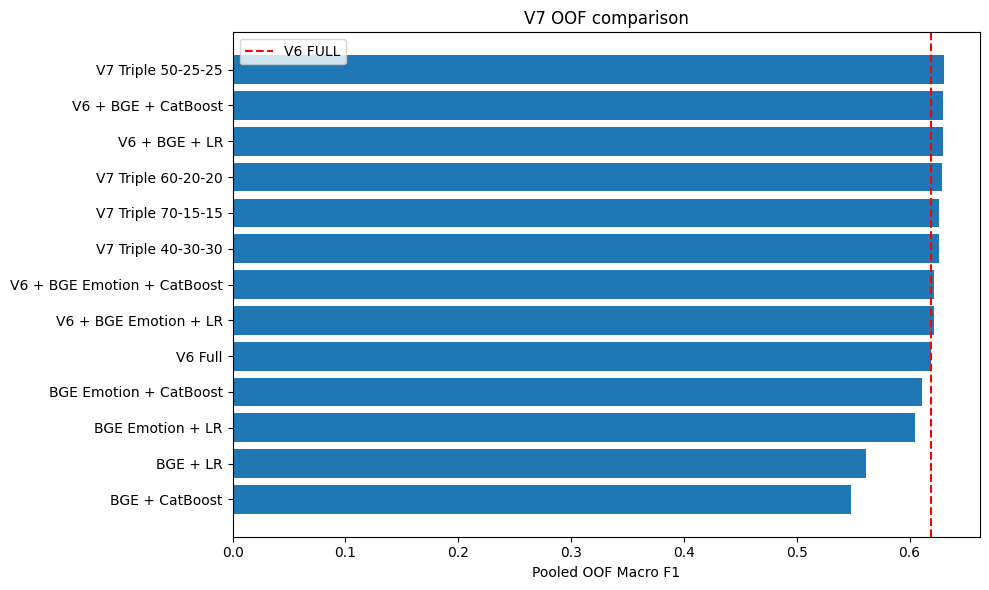

Selected primary: V7 Triple 50-25-25 | exploratory highest: V7 Triple 50-25-25


In [9]:
v7_candidates={'V6 Full':v6_oof}
v7_candidates_test={'V6 Full':v6_test}
for name in V7_MODES:
    v7_candidates[name]=v7_oof[name]; v7_candidates_test[name]=v7_test[name]
    v7_candidates['V6 + '+name]=.5*v6_oof+.5*v7_oof[name]
    v7_candidates_test['V6 + '+name]=.5*v6_test+.5*v7_test[name]

TRIPLES={'V7 Triple 50-25-25':(.5,.25,.25),'V7 Triple 60-20-20':(.6,.2,.2),
         'V7 Triple 70-15-15':(.7,.15,.15),'V7 Triple 40-30-30':(.4,.3,.3)}
for name,(w1,w2,w3) in TRIPLES.items():
    assert np.isclose(w1+w2+w3,1)
    v7_candidates[name]=w1*v6_oof+w2*v7_oof['BGE + LR']+w3*v7_oof['BGE + CatBoost']
    v7_candidates_test[name]=w1*v6_test+w2*v7_test['BGE + LR']+w3*v7_test['BGE + CatBoost']

def macro(y,p): return f1_score(y,p,labels=LABELS,average='macro',zero_division=0)
preds={name:np.asarray(LABELS)[p.argmax(1)] for name,p in v7_candidates.items()}
base=preds['V6 Full']
base_f1=macro(train_label,base)
rows,fold_rows,per_class=[],[],[]
for name,p in v7_candidates.items():
    validate_probs(p,len(train_df)); validate_probs(v7_candidates_test[name],len(test_df))
    pred=preds[name]
    scores=[]; deltas=[]
    for k,(_,h) in enumerate(folds,1):
        score=macro(train_label[h],pred[h]); b=macro(train_label[h],base[h]); scores.append(score); deltas.append(score-b)
        fold_rows.append({'Model':name,'Fold':k,'Macro F1':score,'V6 Baseline':b,'Delta':score-b})
    rep=classification_report(train_label,pred,labels=LABELS,output_dict=True,zero_division=0)
    for label in LABELS:
        per_class.append({'Model':name,'Emotion':label,'Precision':rep[label]['precision'],
            'Recall':rep[label]['recall'],'F1':rep[label]['f1-score'],'Support':rep[label]['support']})
    rows.append({'Model':name,'Accuracy':accuracy_score(train_label,pred),'Macro F1':macro(train_label,pred),
         'Weighted F1':f1_score(train_label,pred,average='weighted'),'Mean Fold F1':np.mean(scores),
         'Std Fold F1':np.std(scores,ddof=1),'Log Loss':log_loss(train_label,p,labels=LABELS),
         'Disgust Precision':rep['disgust']['precision'],'Disgust Recall':rep['disgust']['recall'],
         'Disgust F1':rep['disgust']['f1-score'],'Delta vs V6':macro(train_label,pred)-base_f1,
         'Positive Folds':int(np.sum(np.asarray(deltas)>0)),'Predicted Classes':len(set(pred))})

comparison=pd.DataFrame(rows).sort_values('Macro F1',ascending=False).reset_index(drop=True)
fold_table=pd.DataFrame(fold_rows); per_class=pd.DataFrame(per_class)
display(comparison.round(4))
display(fold_table.pivot(index='Model',columns='Fold',values='Delta').round(4))
display(per_class.pivot(index='Emotion',columns='Model',values='F1').round(4))
comparison.to_csv(OUT/'v7_comparison.csv',index=False)
fold_table.to_csv(OUT/'v7_paired_fold_deltas.csv',index=False)
per_class.to_csv(OUT/'v7_per_class_oof.csv',index=False)

plot_df=comparison.sort_values('Macro F1')
plt.figure(figsize=(10,6)); plt.barh(plot_df.Model, plot_df['Macro F1'])
plt.axvline(base_f1,color='red',linestyle='--',label='V6 FULL'); plt.xlabel('Pooled OOF Macro F1')
plt.title('V7 OOF comparison'); plt.legend(); plt.tight_layout(); plt.show(); plt.close()
print('Selected primary:',SUBMIT_MODEL,'| exploratory highest:',comparison.iloc[0]['Model'])


### 3.5 Paired verification, error complementarity and confidence intervals
We examine the three final ensemble candidates versus V6, with paired bootstrap resampling stratified by true emotion. Intervals describe finite-sample variation conditional on fixed predictions (not retraining variation). The same OOF data was already used in exploratory selection, so these are diagnostic intervals, not independent tests. Report the raw disagreement counts rather than equating correlation with causality.

,Model,Pooled OOF Delta,CI Lower,CI Upper,Positive Folds
0,V6 + BGE + CatBoost,0.0106,0.0037,0.0178,5
1,V6 + BGE + LR,0.0104,0.0018,0.0195,5
2,V7 Triple 50-25-25,0.0115,0.0036,0.0196,5


,Branch,Both correct,Only V6 correct,Only branch correct,Both wrong,Ensemble fixes both wrong,Ensemble loses both correct,Agreement
0,BGE + LR,1666,472,285,937,5,0,0.666964
1,BGE + CatBoost,1638,500,283,939,9,0,0.654762
2,BGE Emotion + LR,1918,220,167,1055,2,0,0.819643
3,BGE Emotion + CatBoost,1990,148,118,1104,2,0,0.873214


V6 Full
              precision    recall  f1-score   support

       anger       0.57      0.63      0.60       674
     disgust       0.53      0.41      0.47       454
        fear       0.67      0.64      0.65       288
         joy       0.72      0.78      0.75       875
     sadness       0.62      0.63      0.63       628
    surprise       0.66      0.59      0.62       441

    accuracy                           0.64      3360
   macro avg       0.63      0.61      0.62      3360
weighted avg       0.63      0.64      0.63      3360



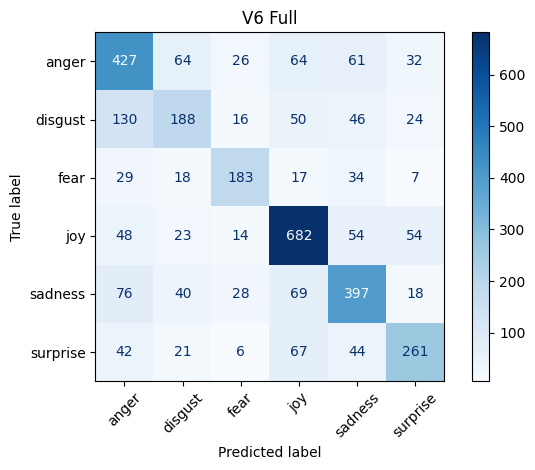

V7 Triple 50-25-25
              precision    recall  f1-score   support

       anger       0.58      0.65      0.61       674
     disgust       0.55      0.42      0.48       454
        fear       0.67      0.64      0.65       288
         joy       0.73      0.79      0.76       875
     sadness       0.66      0.66      0.66       628
    surprise       0.65      0.61      0.63       441

    accuracy                           0.65      3360
   macro avg       0.64      0.63      0.63      3360
weighted avg       0.65      0.65      0.65      3360



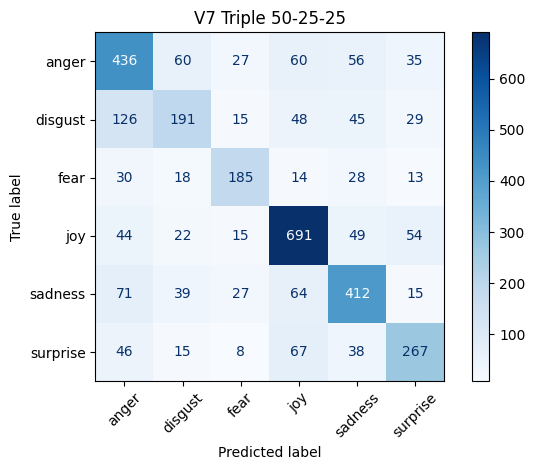

predicted_label
anger       126
joy          48
sadness      45
surprise     29
fear         15
dtype: int64

In [10]:
FINALISTS=['V6 + BGE + CatBoost','V6 + BGE + LR','V7 Triple 50-25-25']
rng=np.random.default_rng(SEED)
class_indices=[np.flatnonzero(train_label==label) for label in LABELS]
boot_ix=[np.concatenate([rng.choice(ids,len(ids),replace=True) for ids in class_indices]) for _ in range(1000)]
base_boot=np.array([macro(train_label[ix],base[ix]) for ix in boot_ix])
verification=[]
for name in FINALISTS:
    pred=preds[name]
    boot=np.array([macro(train_label[ix],pred[ix]) for ix in boot_ix])-base_boot
    verification.append({'Model':name,'Pooled OOF Delta':macro(train_label,pred)-base_f1,
        'CI Lower':np.quantile(boot,.025),'CI Upper':np.quantile(boot,.975),
        'Positive Folds':int((fold_table.loc[fold_table.Model==name,'Delta']>0).sum())})
verification=pd.DataFrame(verification)
display(verification.round(4)); verification.to_csv(OUT/'v7_verification_report.csv',index=False)

overlap=[]
for name in V7_MODES:
    a=base==train_label; b=preds[name]==train_label; c=preds['V6 + '+name]==train_label
    overlap.append({'Branch':name,'Both correct':int((a&b).sum()),'Only V6 correct':int((a&~b).sum()),
        'Only branch correct':int((~a&b).sum()),'Both wrong':int((~a&~b).sum()),
        'Ensemble fixes both wrong':int((~a&~b&c).sum()),'Ensemble loses both correct':int((a&b&~c).sum()),
        'Agreement':float(np.mean(base==preds[name]))})
overlap=pd.DataFrame(overlap); display(overlap); overlap.to_csv(OUT/'v7_error_overlap.csv',index=False)
for name in ['V6 Full',SUBMIT_MODEL]:
    print(name); print(classification_report(train_label,preds[name],labels=LABELS,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(train_label,preds[name],labels=LABELS,xticks_rotation=45,cmap='Blues')
    plt.title(name); plt.tight_layout(); plt.show(); plt.close()

error_df=pd.DataFrame({'post_id':train_df.post_id.to_numpy(),'text':train_text,'true_label':train_label,
    'predicted_label':preds[SUBMIT_MODEL],'confidence':v7_candidates[SUBMIT_MODEL].max(1),'fold':fold_id})
error_df=error_df[error_df.true_label!=error_df.predicted_label]
display(error_df[error_df.true_label=='disgust'].groupby('predicted_label').size().sort_values(ascending=False))
error_df.to_csv(OUT/'v7_primary_errors.csv',index=False)


### 3.6 Save candidate OOF and test probabilities for V8
Save named arrays in canonical label order with explicit IDs and fold numbers. This allows later ensemble studies without repeating GPU training; retaining all sources also makes the experiment auditable.

In [11]:
archive=OUT/'v7_probabilities'; archive.mkdir(exist_ok=True)
for name,p in v7_candidates.items():
    oof_df=pd.DataFrame({'post_id':train_df.post_id.to_numpy(),'fold':fold_id,'true_label':train_label,'predicted_label':preds[name]})
    test_audit=pd.DataFrame({'post_id':test_df.post_id.to_numpy()})
    for i,label in enumerate(LABELS):
        oof_df[f'p_{label}']=p[:,i]; test_audit[f'p_{label}']=v7_candidates_test[name][:,i]
    oof_df.to_csv(archive/f'{slug(name)}_oof_predictions.csv',index=False)
    test_audit.to_csv(archive/f'{slug(name)}_test_probabilities.csv',index=False)
print('Saved probability artifacts:',archive)


Saved probability artifacts: /kaggle/working/v7_probabilities


### 3.7 Kaggle submission — exact format
Primary selected configuration is set in the first cell. If changing it after training, set `SUBMIT_MODEL` here and rerun only this cell. Also save the alternate 50:50 submissions in a subfolder for manual comparison. The root submission remains the designated model.

In [12]:
# SUBMIT_MODEL = 'V6 + BGE + CatBoost'  # uncomment to choose an alternate
assert SUBMIT_MODEL in v7_candidates_test
def make_submission(name):
    p=v7_candidates_test[name]; validate_probs(p,len(test_df))
    assert len(set(preds[name]))==len(LABELS), 'OOF class collapse'
    pred=np.asarray(LABELS)[p.argmax(1)]
    assert len(set(pred))>1, 'Test class collapse'
    mapping=dict(zip(test_df.post_id.astype(str),pred))
    d=pd.DataFrame({'id':sample.post_id.astype(str),'label':sample.post_id.astype(str).map(mapping)})
    assert d.shape==(1440,2) and d.columns.tolist()==['id','label']
    assert d.id.is_unique and d.notna().all().all() and set(d.label)<=set(LABELS)
    return d.reset_index(drop=True)

alt=OUT/'v7_candidate_submissions'; alt.mkdir(exist_ok=True)
for name in FINALISTS: make_submission(name).to_csv(alt/f'submission_{slug(name)}.csv',index=False)
submission=make_submission(SUBMIT_MODEL)
path=OUT/'submission.csv'; submission.to_csv(path,index=False,encoding='utf-8')
reloaded=pd.read_csv(path,dtype={'id':str})
assert reloaded.equals(submission) and path.read_text().splitlines()[0]=='id,label'
assert reloaded.id.tolist()==sample.post_id.astype(str).tolist()
print('SUCCESS:',path,'| rows',len(reloaded),'| selected',SUBMIT_MODEL)
print('OOF Macro F1:',round(macro(train_label,preds[SUBMIT_MODEL]),4))
print(reloaded.label.value_counts()); display(reloaded.head())


SUCCESS: /kaggle/working/submission.csv | rows 1440 | selected V7 Triple 50-25-25
OOF Macro F1: 0.6309
label
joy         380
anger       350
sadness     280
surprise    177
disgust     141
fear        112
Name: count, dtype: int64


,id,label
0,xyzx9jp,surprise
1,l3vzzxt,anger
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise


---
## Final Homework Submission Checklist

- [ ] Confirm this notebook has the required filename: **`DM2026-Lab2-Homework.ipynb`**.
- [ ] Confirm the report and competition code describe the **same V7 model**: 50% V6 FULL + 25% BGE LR + 25% BGE CatBoost.
- [ ] Keep only actual confirmed results in the report: **V7 OOF Macro F1 0.6309** and **Public Score 0.6288**. Add Private Score/ranking only if verified.
- [ ] Verify the GitHub account ID and confirm that `pics/pic_ranking.png` is from the Private Leaderboard tab.
- [x] Include the nine original AI prompts supplied from the project discussion.
- [ ] If rerunning, attach the competition dataset and optional V6 OOF/test probability CSVs; enable GPU and use the working Kaggle runtime. In a clean environment the notebook may retrain V6 and V7 and require substantial GPU resources.
- [ ] Check the generated `/kaggle/working/submission.csv`: **1,440 rows, exactly `id,label`, correct sample-submission order**.
- [ ] Push the notebook and the competition code to the course repository.
- [ ] Include `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, and `DM2026-Lab2-Homework.ipynb` in the required ZIP, along with **both encrypted session logs** under `session_logs/` and `pics/pic_ranking.png`.
- [ ] Open the ZIP and confirm the encrypted logs and screenshot are actually included. The ZIP is separate from the git-ignored files in the public repository.

### Reference resources

- [BGE model card — BAAI/bge-base-en-v1.5](https://huggingface.co/BAAI/bge-base-en-v1.5)
- [Hartmann emotion model card — emotion-english-distilroberta-base](https://huggingface.co/j-hartmann/emotion-english-distilroberta-base)
- [CatBoost official documentation](https://catboost.ai/en/docs/)
- [Scikit-learn StratifiedKFold documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)

> **Reproducibility:** This notebook retains the original V7 model implementation. Report values above are previously observed, not results created by this report editing operation. No Private Leaderboard score is asserted.